### Module 4 Homework - EOF Analysis

1. Create a dataset that contains the monthly means of Sea Surface Temperature anomalies and total column water vapor from Jan 1979-Dec 2024 over the Pacific Basin (65°N to 65°S, 120°E to 60°W) masked out over land - save this to your computer. The data and land sea mask is available here: https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download

In [ ]:
import requests
import pandas as pd
# convert the response as a structured json
import json
import numpy as np
from datetime import datetime
# import time for sleeping
import time
import cartopy.crs as ccrs
import xarray as xr
import matplotlib.pyplot as plt
from eofs.xarray import Eof

In [ ]:
# download ERA5 SST and TCWV nc files using CDSAPI
import cdsapi

dataset = "reanalysis-era5-single-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": [
        "sea_surface_temperature",
        "total_column_water_vapour"
    ],
    "year": [
        "1979", "1980", "1981",
        "1982", "1983", "1984",
        "1985", "1986", "1987",
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024"
    ],
    "month": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12"
    ],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived"
}

client = cdsapi.Client(url='https://cds.climate.copernicus.eu/api',
                       key='f98f7868-6839-459b-9d51-fc45334963d8')
client.retrieve(dataset, request).download()

2025-10-19 06:27:08,770 INFO Request ID is cf446bcf-1b1a-4f94-8535-2cefa8880e76
2025-10-19 06:27:08,939 INFO status has been updated to accepted
2025-10-19 06:27:42,479 INFO status has been updated to running
2025-10-19 06:31:29,435 INFO status has been updated to successful


'112c9dfac39142028bd32c52294d52ba.nc'

In [ ]:
## download land-sea mask from 1979 dir
import cdsapi

dataset = "reanalysis-era5-single-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": ["land_sea_mask"],
    "year": ["1979"],
    "month": ["01"],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived"
}

client = cdsapi.Client(url='https://cds.climate.copernicus.eu/api',
                       key='f98f7868-6839-459b-9d51-fc45334963d8')
client.retrieve(dataset, request).download()

2025-10-20 05:18:38,435 INFO Request ID is 38405c41-0ede-4f43-b5af-336915d57e96
2025-10-20 05:18:38,617 INFO status has been updated to accepted
2025-10-20 05:18:53,619 INFO status has been updated to running
2025-10-20 05:19:01,386 INFO status has been updated to successful


'3ecffe4b200dc77240fe3546ebede057.nc'

In [ ]:
# open land-sea mask
mask = xr.open_dataset('3ecffe4b200dc77240fe3546ebede057.nc', engine='netcdf4')
# round values to 0 or 1 for binary 2d mask of sea pixels
mask_bin = np.round(mask.sel(latitude=slice(65,-65), longitude=slice(120,180+120)).lsm.values)[0]

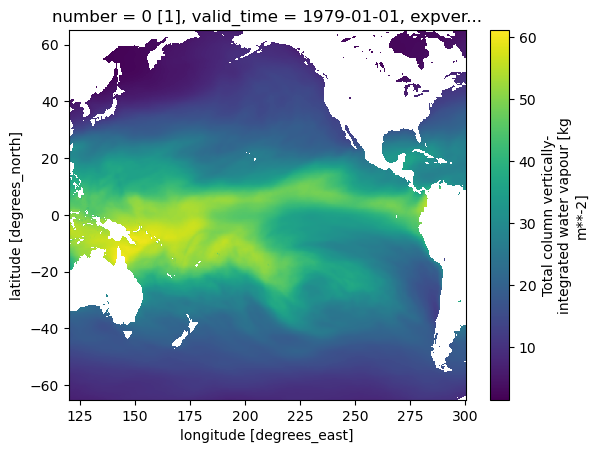

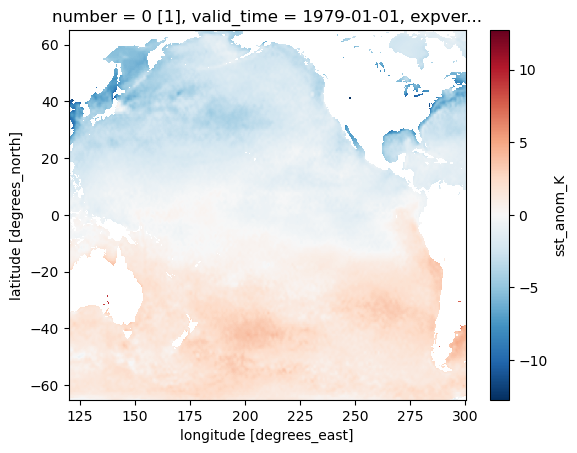

In [ ]:
# open SST and TCWV dataset
ds = xr.open_dataset('112c9dfac39142028bd32c52294d52ba.nc', engine='netcdf4')
# rename time variable
#ds = ds.rename_dims({'valid_time': 't'})
#ds = ds.rename_vars({'valid_time': 't'})
# subset lat, lon for Pacific Ocean
ds = ds.sel(latitude=slice(65,-65), longitude=slice(120,180+120))
# apply land-sea mask (inverted boolean values with ~)
ds_mask = ds.where(~mask_bin.astype(bool), np.nan)

# subset Total Column Water Vapor as new variable
tcwv = ds_mask.tcwv
# subset SST anomalies as new variable
sst_anom = ds_mask.sst - ds_mask.sst.mean(dim='valid_time')
sst_anom = sst_anom.rename('sst_anom_K')

# plot TCWV preview to confirm masking
tcwv.isel(valid_time=0).plot()
plt.figure()
sst_anom.isel(valid_time=0).plot()

2. From the dataset shown in 1, compute anomalies by deseasonalizing the data (remove the mean monthly anomaly from the annual mean from each point) and detrend the data. Then, standardize the SST anomalies. Standardization means subtract the long term mean and divide by the standard deviation, which can be accomplished using the methods described here: 6.3. Preprocessing data — scikit-learn 1.1.2 documentation.

In [ ]:
def _time_as_float(time: xr.DataArray, time_dim: str) -> xr.DataArray:
    # numeric seconds since first timestamp (keeps numbers small)
    return (time - time.isel({time_dim: 0})).astype("timedelta64[s]").astype("int64").astype("float64")

def linear_detrend(obj: xr.DataArray | xr.Dataset, time_dim: str = "valid_time") -> xr.DataArray | xr.Dataset:
    """
    Remove a linear trend y ~ s*(t - t̄_valid) + ȳ_valid at each grid point.
    Closed-form LS using reductions; dask-friendly; handles NaNs.
    """
    t = _time_as_float(obj[time_dim], time_dim)  # (time,)
    def _detrend_da(da: xr.DataArray) -> xr.DataArray:
        da = da.sortby(time_dim).astype("float32")
        if hasattr(da.data, "chunks"):
            da = da.chunk({time_dim: -1})  # one chunk along time
        mask = da.notnull()                                # (time, ...)
        t_b = t.broadcast_like(da)                         # (time, ...)
        t_mean_valid = t_b.where(mask).mean(time_dim, skipna=True)
        tc = t_b - t_mean_valid                            # centered time per point
        num = (da * tc).sum(time_dim, skipna=True)
        den = (tc**2).sum(time_dim, skipna=True)
        slope = xr.where(den > 0, num / den, 0.0)
        ybar  = da.mean(time_dim, skipna=True)
        trend = slope * (t_b - t_mean_valid) + ybar
        return (da - trend).astype("float32")
    return obj.map(_detrend_da) if isinstance(obj, xr.Dataset) else _detrend_da(obj)

def monthly_anom_and_z(
    detr: xr.DataArray | xr.Dataset,
    time_dim: str = "valid_time",
    base_period: tuple[str, str] | None = None,
    ddof: int = 1,
    eps: float = 1e-6,
):
    """
    From linearly-detrended data, remove monthly climatology and compute monthly z-scores.
    Returns (anom, z). Works for Dataset or DataArray.
    """
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)})
    key = f"{time_dim}.month"

    clim_mean = clim_src.groupby(key).mean(time_dim, skipna=True)
    anom = detr.groupby(key) - clim_mean

    clim_std = clim_src.groupby(key).std(time_dim, skipna=True, ddof=ddof)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan)
    z = anom.groupby(key) / safe_std
    return anom, z

/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 

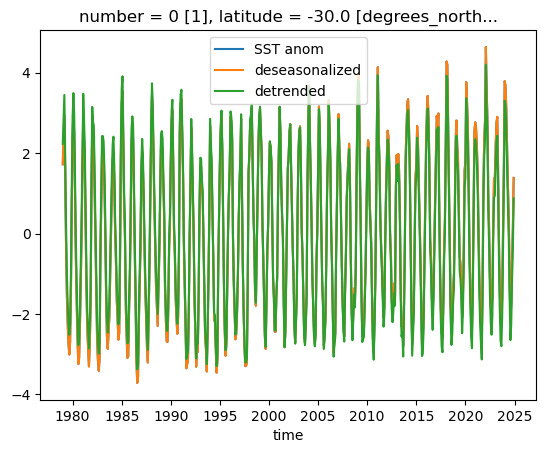

In [ ]:
# deseasonalize SST anomaly data
sst_anom_des = sst_anom - sst_anom.mean('valid_time')
# detrend SST anomaly data
sst_anom_detr = linear_detrend(sst_anom_des)
# standardize detrended SST anomalies
sst_anom_standard, sst_anom_z = monthly_anom_and_z(sst_anom_detr)

# quick plot to compare corrections
sst_anom.sel(latitude=-30,longitude=180).plot(label='SST anom')
sst_anom_des.sel(latitude=-30,longitude=180).plot(label='deseasonalized')
sst_anom_detr.sel(latitude=-30,longitude=180).plot(label='detrended')
plt.legend()

/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 

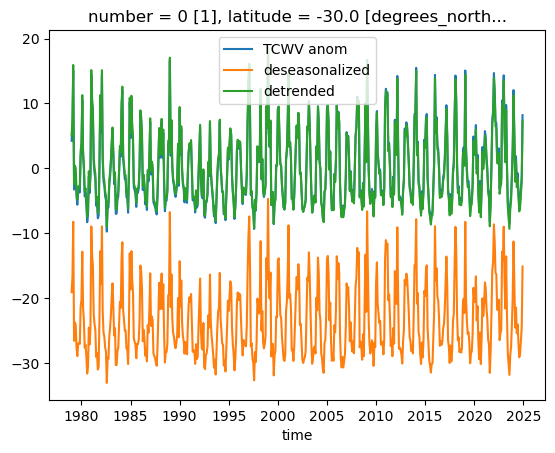

In [ ]:
# deseasonalize TCWV anomaly data
tcwv_anom = tcwv - tcwv.mean('valid_time')
tcwv_anom_des = tcwv_anom - tcwv.mean('valid_time')
# detrend TCWV anomaly data
tcwv_anom_detr = linear_detrend(tcwv_anom_des)
# standardize detrended TCWV anomalies
tcwv_anom_standard, tcwv_anom_z = monthly_anom_and_z(tcwv_anom_detr)

# quick plot to compare corrections
tcwv_anom.sel(latitude=-30,longitude=180).plot(label='TCWV anom')
tcwv_anom_des.sel(latitude=-30,longitude=180).plot(label='deseasonalized')
tcwv_anom_detr.sel(latitude=-30,longitude=180).plot(label='detrended')
plt.legend()

3. Perform an EOF analysis on the SST anomalies and plot a map of the first 5 EOFs, following M04N05.

In [ ]:
# apply cosine latitude weights
test = sst_anom_z.drop_vars(names=['number', 'expver', 'month'])
coslat = np.cos(np.deg2rad(test.coords['latitude'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
# use EOF solver for first 5 modes
solver = Eof(test, weights=wgts)
# Retrieve the leading EOF, expressed as the correlation between the leading
# PC time series and the input SST anomalies at each grid point, and the
# leading PC time series itself
eof1 = solver.eofsAsCorrelation(neofs=2)
pc1 = solver.pcs(npcs=2, pcscaling=1)

/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/home/mheslar2/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/home/mheslar2/envs/xarray-climate/l

Text(0.45, 1.0, 'The First 5 EOFs Expressed as Correlation')

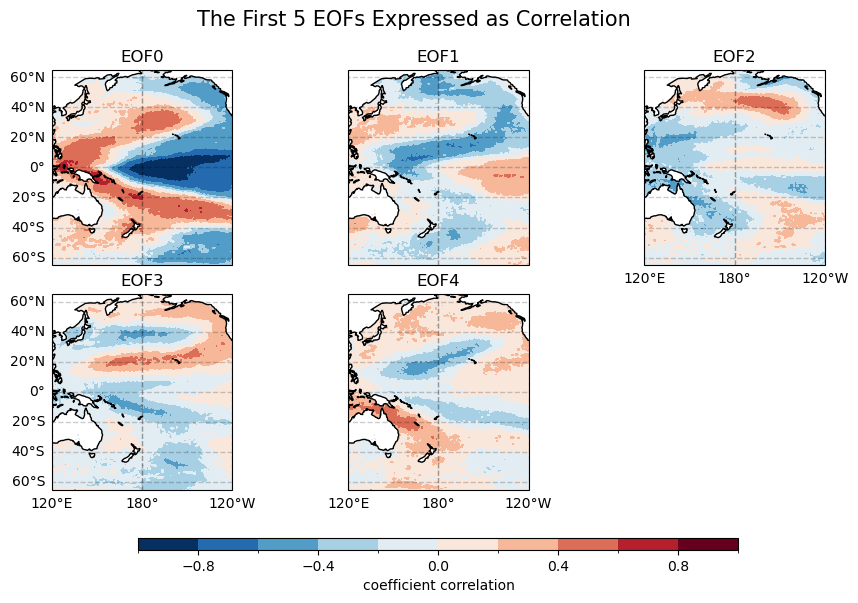

In [ ]:
# plot the first 5 EOFs
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
from cartopy.mpl.ticker import (LongitudeFormatter, LatitudeFormatter,
                                LatitudeLocator, LongitudeLocator)

eof_sst = [eof1.isel(mode=i) for i in range (5)]

proj = ccrs.PlateCarree(central_longitude = 190)
fig, axes = plt.subplots(
    2, 3, figsize=(10, 6),
    subplot_kw={'projection': proj,
    "aspect": 1},
)
clevs = np.linspace(-1, 1, 11)

for i, (img, ax) in enumerate(zip(eof_sst,[y for x in axes for y in x])):

    plot_eof_sst = img.plot.contourf(
        ax=ax, levels=clevs,
        transform=ccrs.PlateCarree(),
        cmap=plt.cm.RdBu_r,
        add_colorbar=False,
    )
    ax.set_title("EOF"+ str(img.mode.to_dict()["data"]))
    ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')

    gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=1, color='black', alpha=0.2, linestyle="--")

    gl.xlocator = LongitudeLocator()
    gl.ylocator = LatitudeLocator()
    gl.xformatter = LongitudeFormatter()
    gl.yformatter = LatitudeFormatter()

    if i>= 2:
        gl.bottom_labels = True
    if i == 0 or i == 3:
        gl.left_labels = True

# delete unwanted figures
fig.delaxes(axes[1][2])

# adjust the location of the subplots on the page to make room for the colorbar
fig.subplots_adjust(bottom=0.2, top=0.9, left=0.05, right=0.9,
                    wspace=0.15, hspace=0.15)

# add a colorbar axis at the bottom of the graph
cbar_ax = fig.add_axes([0.175, 0.1, 0.6, 0.02]) #left, bottom, width, height

# draw the colorbar
cbar=fig.colorbar(plot_eof_sst, cax=cbar_ax, orientation='horizontal')
cbar.set_label('coefficient correlation')

# add a big title at the top
plt.suptitle("The First 5 EOFs Expressed as Correlation", x= 0.45, y=1.0, fontsize = 15)

4. Plot the percent of variance explained by the first 10 EOFs.

(5.524231885566707e-16, 0.19594654440879822)

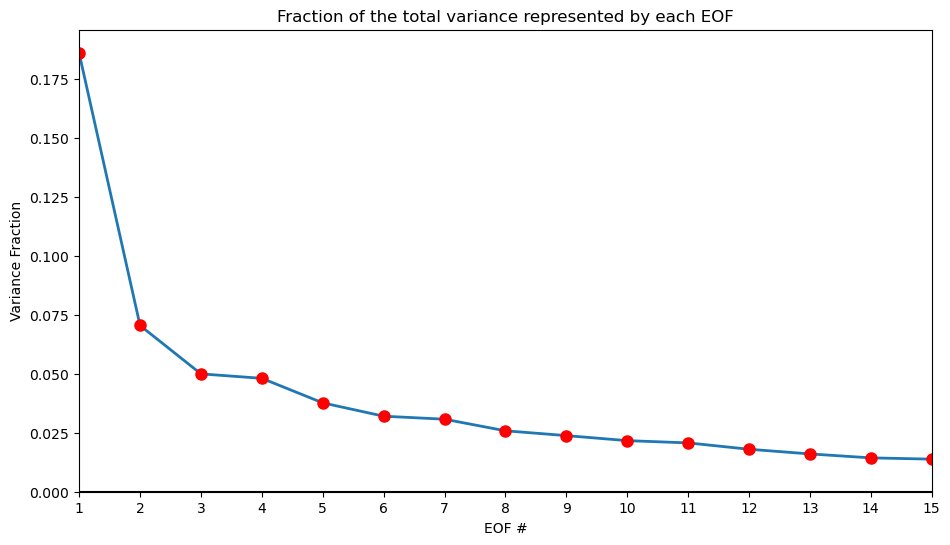

In [ ]:
# put EOF results in terms of percent of variance
varfrac = solver.varianceFraction()

# Plot the fraction of variance explained by each EOF
plt.figure(figsize=(11,6))
eof_num = range(1, 16)
plt.plot(eof_num, varfrac[0:15], linewidth=2)
plt.plot(eof_num, varfrac[0:15], linestyle='None', marker="o", color='r', markersize=8)
plt.axhline(0, color='k')
plt.xticks(range(1, 16))
plt.title('Fraction of the total variance represented by each EOF')
plt.xlabel('EOF #')
plt.ylabel('Variance Fraction')
plt.xlim(1, 15)
plt.ylim(np.min(varfrac), np.max(varfrac)+0.01)



5. Reconstruct the SST field using the first 5 EOFs and plot a map of the Pearson's correlation coefficient (xarray.corr) of the reconstructed monthly time series and the "observed" SST time series.

In [ ]:
reconstruction = solver.reconstructedField(5)
reconstruction

<xarray.DataArray (valid_time: 552, latitude: 521, longitude: 481)> Size: 553MB
array([[[            nan,             nan,             nan, ...,
          1.63498402e-01,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        ...,
        [-8.27696472e-02, -9.34327543e-02, -1.03463143e-01, ...,
         -1.06614016e-01, -1.12419464e-01, -1.17681108e-01],
        [-9.56816897e-02, -1.05395295e-01, -1.13981947e-01, ...,
         -1.33886129e-01, -1.31308556e-01, -1.28278106e-01],
        [-1.09180048e-01, -1.13782234e-01, -1.14599772e-01, ...,
         -1.41078159e-01, -1.33534998e-01, -1.28374293e-01]],

       [[            nan,             nan,             nan, ...,
          1.94313541e-01,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
...
          2.76218653e-01,  2.62812674e-01,  2.48489469e-01],
        [ 6.04633801e-03, -2.55534280e-04, -6.07399084e-03, ...,
          2.82727122e-01,  2.71996647e-01,  2.60357529e-01],
        [-1.66110378e-02, -1.86903067e-02, -1.61705576e-02, ...,
          2.73708045e-01,  2.72602409e-01,  2.65566021e-01]],

       [[            nan,             nan,             nan, ...,
          4.51761037e-02,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        ...,
        [ 5.47136832e-03,  1.08495886e-02,  1.54566113e-02, ...,
         -1.20929107e-01, -1.31928757e-01, -1.42900392e-01],
        [ 5.69780311e-03,  2.35605845e-03, -9.63115483e-04, ...,
         -1.03008211e-01, -1.19965434e-01, -1.36389717e-01],
        [-7.03149708e-03, -1.02602169e-02, -1.21983821e-02, ...,
         -1.01039745e-01, -1.13875180e-01, -1.28353655e-01]]],
      shape=(552, 521, 481), dtype=float32)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 4kB 120.0 120.2 120.5 ... 239.5 239.8 240.0
Attributes:
    long_name:  None_reconstructed_with_5_EOFs

TypeError: descriptor 'date' for 'datetime.datetime' objects doesn't apply to a 'str' object

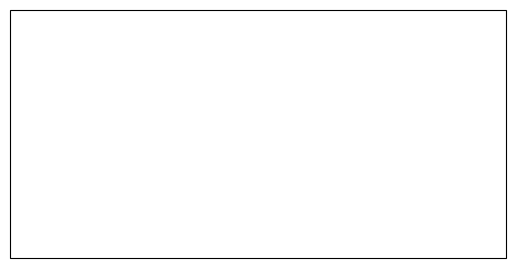

In [ ]:
# Plot the leading EOF expressed as correlation in the Pacific domain.
clevs = np.linspace(-3, 3, 21)
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = sst_anom.sel(vaild_time='1998-01-15', method='nearest').plot.contourf(ax=ax, levels=clevs,
                    cmap=plt.cm.RdBu_r, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('SST Anomalies observed', fontsize=12)


6. Compute a map of the Pearson's correlation coefficient between SST EOF1 and monthly mean detrended, deseasonalized, and standardized monthly mean column water vapor anomalies (don't mask these over land for the plot). See anything interesting?